# ACh (NBM) and the BWM LD1, within mice

The same question and methods as `4_da_ld1_within_mouse` (session LD1 from the BWM projection; DA → ACh measures per
fiber-session from `ld1_neural.py`; within-fiber residuals, controls added step by step), for the **NBM-ACh** fibers.

Two things specific to ACh:
- **Bilateral mice.** Two of the mice carry a left and a right NBM fiber recorded in the same sessions, so their LD1
  is shared. Tests therefore use `unit='mouse'`: residualised within each fiber, averaged over a mouse's fibers per
  session, LD1 permuted within mouse (a session counts once). Traces are averaged over a mouse's fibers first too.
- **Left vs right differ** (`nm-coupling-is-fiber-specific`: bilateral NBM fibers differ more than mice do), so the
  last section shows each fiber of the bilateral mice separately.

Small: 4 mice with ≥ 5 sessions, 6 fibers, 43 sessions. Read effects as directions, not as established.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nm_projection as npj
import ld1_neural as L

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
emb, sc = npj.frame()
A = npj.project(emb, sc, protocol=None)
T = L.session_table(A, targets=('NBM-ACh',))
PH = ['baseline', 'stim', 'stim_slow', 'reward', 'error', 'reward_hard']
CP = [c for c in T if c.startswith(('β ', 'R² '))]
BASE = ('day', 'protocol')
T.groupby('fiber').agg(sessions=('eid', 'size'), LD1_sd=('LD1', 'std'), days=('day_n', lambda s: s.max() - s.min())).round(2)

,sessions,LD1_sd,days
fiber,,,
ZFM-08751 NBM,15,1.22,39
ZFM-08813 NBM,7,2.30,18
ZFM-09768 NBM-l,11,0.75,29
ZFM-09768 NBM-r,11,0.75,29
ZFM-09772 NBM-l,9,1.33,25
ZFM-09772 NBM-r,10,1.31,25


In [2]:
#%%
""" SANITY: within mouse, session LD1 vs the same session's behaviour (wheel measures partly circular) """
L.within_fiber(T, ['log_reaction', 'correct', 'wheel_gate', 'paw_gate', 'wheel_speed_Quiescence', 'switches'],
               controls=BASE, n_perm=2000, unit='mouse').round(3)

,measure,r,p,n_sessions,n_fibers,n_mice,q
0,log_reaction,-0.310,0.009,43,6,4,0.019
1,correct,0.462,0.013,43,6,4,0.019
2,wheel_gate,-0.478,0.027,43,6,4,0.032
3,paw_gate,-0.590,0.000,43,6,4,0.003
4,wheel_speed_Quiescence,0.585,0.001,43,6,4,0.003
5,switches,-0.006,0.974,43,6,4,0.974


In [3]:
#%%
""" MAIN: LD1 vs the ACh measures, controls added step by step (r, BH q over the measures; unit = mouse-session) """
STEPS = {'day + protocol': BASE, '+ RT + accuracy': BASE + ('log_reaction', 'correct'),
         '+ quiescence wheel': BASE + ('log_reaction', 'correct', 'wheel_speed_Quiescence')}
RES = {k: L.within_fiber(T, PH + CP, controls=c, n_perm=5000, unit='mouse').set_index('measure') for k, c in STEPS.items()}
pd.concat({k: v[['r', 'p', 'q']] for k, v in RES.items()}, axis=1).round(3)

day + protocol               + RT + accuracy               + quiescence wheel              
                                       r      p      q               r      p      q                  r      p      q
measure                                                                                                              
baseline                          -0.008  0.956  0.956          -0.032  0.850  0.966             -0.039  0.830  0.918
stim                               0.154  0.337  0.554           0.097  0.597  0.836              0.072  0.725  0.918
stim_slow                         -0.171  0.237  0.508          -0.131  0.428  0.715             -0.210  0.249  0.523
reward                            -0.165  0.343  0.554          -0.144  0.432  0.715             -0.195  0.315  0.601
error                             -0.072  0.635  0.784          -0.074  0.661  0.864             -0.100  0.587  0.905
reward_hard                        0.225  0.165  0.508           0.397  0.025  0.171              0.467  0.011  0.192
β paw 0 · pre-stim                -0.294  0.063  0.508          -0.286  0.113  0.263             -0.326  0.093  0.247
β whisking · pre-stim              0.308  0.044  0.508           0.394  0.018  0.171              0.412  0.022  0.192
β licking · pre-stim               0.084  0.707  0.825           0.188  0.477  0.715              0.034  0.918  0.918
β paw 0 · post-stim               -0.242  0.100  0.508          -0.304  0.068  0.178             -0.304  0.103  0.247
β whisking · post-stim             0.185  0.266  0.508           0.133  0.451  0.715              0.100  0.603  0.905
β licking · post-stim              0.189  0.235  0.508           0.341  0.048  0.171              0.302  0.106  0.247
β paw 0 · post-fb                  0.244  0.135  0.508           0.007  0.966  0.966             -0.029  0.871  0.918
β whisking · post-fb              -0.104  0.496  0.694           0.010  0.959  0.966              0.042  0.830  0.918
β licking · post-fb                0.056  0.781  0.863           0.012  0.955  0.966             -0.069  0.706  0.918
R² vigor · pre-stim                0.186  0.227  0.508           0.340  0.049  0.171              0.329  0.092  0.247
R² whisker ME · pre-stim           0.254  0.135  0.508           0.383  0.042  0.171              0.380  0.072  0.247
R² vigor · post-stim               0.017  0.914  0.956           0.142  0.451  0.715              0.121  0.561  0.905
R² whisker ME · post-stim         -0.092  0.554  0.728           0.067  0.699  0.864              0.021  0.915  0.918
R² vigor · post-fb                 0.191  0.263  0.508           0.381  0.046  0.171              0.452  0.027  0.192
R² whisker ME · post-fb            0.115  0.472  0.694           0.336  0.066  0.178              0.386  0.050  0.247

In [4]:
#%%
""" the same measures in VTA (4_da_ld1_within_mouse), for direction: + RT + accuracy """
Tv = L.session_table(A, targets=('VTA-DA',))
VTA = L.within_fiber(Tv, PH + CP, controls=STEPS['+ RT + accuracy'], n_perm=2000).set_index('measure')
cmp_ = RES['+ RT + accuracy'][['r', 'p']].rename(columns={'r': 'r ACh', 'p': 'p ACh'}).join(
    VTA[['r', 'q']].rename(columns={'r': 'r VTA', 'q': 'q VTA'}))
print('direction agreement across measures, r(ACh, VTA) =', round(cmp_[['r ACh', 'r VTA']].corr().iloc[0, 1], 2))
cmp_.round(3)

direction agreement across measures, r(ACh, VTA) = 0.31


,r ACh,p ACh,r VTA,q VTA
measure,,,,
baseline,-0.032,0.850,0.074,0.522
stim,0.097,0.597,0.256,0.016
stim_slow,-0.131,0.428,0.131,0.347
reward,-0.144,0.432,-0.162,0.187
error,-0.074,0.661,-0.056,0.569
reward_hard,0.397,0.025,0.081,0.522
β paw 0 · pre-stim,-0.286,0.113,0.187,0.178
β whisking · pre-stim,0.394,0.018,0.351,0.010
β licking · pre-stim,0.188,0.477,0.149,0.455


## Traces binned along LD1

As in notebook 4: each fiber's sessions split into thirds by LD1, averaged within fiber and third; here a bilateral
mouse's two fibers are averaged first, so each **mouse** counts once (shading = SEM across mice).

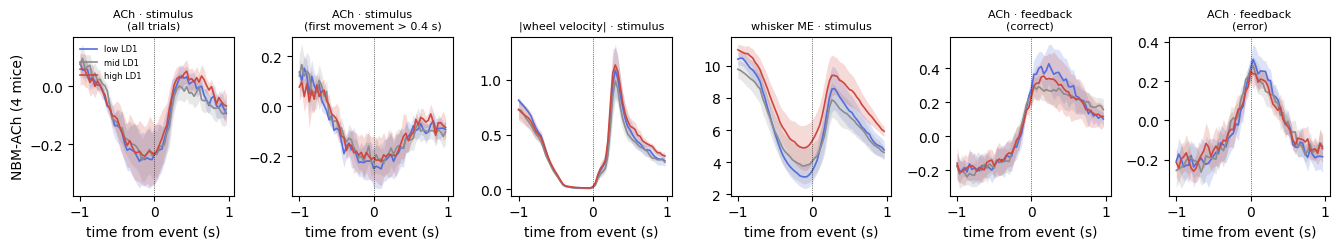

In [5]:
#%%
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import paper_style as ps
TR = L.traces(sorted(T['eid'].unique()))
PANELS = [('stim_all', 'ACh · stimulus\n(all trials)'), ('stim_slow', 'ACh · stimulus\n(first movement > 0.4 s)'),
          ('stim wheel speed', '|wheel velocity| · stimulus'), ('stim whisker ME', 'whisker ME · stimulus'),
          ('fb_correct', 'ACh · feedback\n(correct)'), ('fb_error', 'ACh · feedback\n(error)')]
BIN_COL = [ps.LD1_CMAP(0.08), '0.55', ps.LD1_CMAP(0.92)]
fig, axes = plt.subplots(1, len(PANELS), figsize=(2.25 * len(PANELS), 2.6), sharex=True)
for ax, (key, title) in zip(axes, PANELS):
    t, out = L.binned_traces(T, TR, key, unit='subject')
    for b, (m, se) in out.items():
        ax.plot(t, m, color=BIN_COL[b], lw=1.2, label=['low', 'mid', 'high'][b] + ' LD1')
        ax.fill_between(t, m - se, m + se, color=BIN_COL[b], alpha=0.2, lw=0)
    ax.axvline(0, color='k', lw=0.5, ls=':')
    ax.set_title(title, fontsize=8); ax.set_xlabel('time from event (s)')
axes[0].set_ylabel(f"NBM-ACh ({T['subject'].nunique()} mice)")
axes[0].legend(fontsize=6, frameon=False, loc='upper left')
plt.tight_layout()
pathlib.Path('figures').mkdir(exist_ok=True)
fig.savefig('figures/ach_ld1_traces.png', dpi=250, bbox_inches='tight')
plt.show()

In [6]:
#%%
""" LEFT vs RIGHT in the bilateral mice: each fiber's own within-fiber r (day + protocol + RT + accuracy are too many
covariates for ~10 sessions, so day only) """
bil = T.groupby('subject')['fiber'].nunique()
bil = bil.index[bil > 1]
SHOW = ['stim', 'stim_slow', 'reward', 'β whisking · pre-stim', 'R² vigor · pre-stim', 'R² whisker ME · pre-stim']
S = L.fiber_slopes(T[T['subject'].isin(bil)], SHOW, controls=('day',))
S.pivot(index='measure', columns='fiber', values='r').reindex(SHOW).round(2)

fiber,ZFM-09768 NBM-l,ZFM-09768 NBM-r,ZFM-09772 NBM-l,ZFM-09772 NBM-r
measure,,,,
stim,-0.55,-0.50,-0.29,0.21
stim_slow,-0.85,-0.52,0.27,0.09
reward,-0.65,-0.36,-0.06,0.80
β whisking · pre-stim,0.40,0.06,-0.10,0.06
R² vigor · pre-stim,-0.57,0.13,-0.42,-0.58
R² whisker ME · pre-stim,-0.32,0.12,-0.42,-0.86


## Reading

- **Session LD1 is meaningful here too**: within mouse it tracks the same session's RT (−0.31) and accuracy (+0.46),
  and the movement gating, as in BWM and in DA mice.
- **No ACh measure tracks LD1 after correction** (all q ≥ 0.17 with RT and accuracy controlled; 4 mice, 43 sessions).
- **Nominal hints point the same way as VTA**: whisking coupling before the stimulus (+0.39, p = 0.02; VTA +0.35)
  and vigor / whisker R² before the stimulus (+0.34 / +0.38, p < 0.05; VTA +0.30 / +0.16). Across all measures the
  ACh and VTA profiles agree only loosely (r = 0.31).
- **But they are not consistent across fibers**: in the two bilateral mice, each fiber's own slope (day controlled
  only, ~10 sessions each) scatters in sign between left and right and between mice for every measure shown — the
  pooled nominal effects are not something each fiber shows.
- **Traces**: the three LD1 thirds overlap for ACh around stimulus and feedback; what differs is behaviour (high-LD1
  sessions whisk more around the stimulus).

So: no evidence that ACh signalling changes with LD1 within mice; the data are thin (4 mice) and left / right NBM
fibers disagree, so this is a weak null rather than a clear absence.